In [1]:

import warnings
# Silence all non-breaking environment version warnings completely
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd

# Load your transactional database using the relative pathway
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print(df.shape)
df.head()


(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12-01-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12-01-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12-01-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12-01-2010 08:26,3.39,17850.0,United Kingdom


In [2]:
import warnings
# This safely hides those external dependency version messages completely
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Read your dataset from your local data folder path
df = pd.read_csv("../data/data.csv", encoding="ISO-8859-1")
print("Original shape:", df.shape)



Original shape: (541909, 8)


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.6 MB

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [4]:
rows_start = len(df)

# 1. Remove rows with no customer ID 
df = df.dropna(subset=["CustomerID"])
print("After removing missing CustomerID:", len(df))

# 2. Remove duplicate rows
df = df.drop_duplicates()
print("After removing duplicates:", len(df))

# 3. Remove cancelled orders (invoice numbers starting with 'C')
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
print("After removing cancellations:", len(df))

# 4. Remove negative or zero quantity and price
df = df[(df["Quantity"] > 0) & (df['UnitPrice'] > 0)]
print("After removing bad quantity/price:", len(df))

# 5. Fix data types and add a Revenue column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format='mixed')
df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(f"\nStarted with {rows_start} rows, ended with {len(df)} rows")
df.head()


After removing missing CustomerID: 406829
After removing duplicates: 401604
After removing cancellations: 392732
After removing bad quantity/price: 392692

Started with 541909 rows, ended with 392692 rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [5]:
print("Total revenue:", round(df["Revenue"].sum(), 2))
print("Unique customers:", df["CustomerID"].nunique())
print("Unique orders:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Average order value:", round(df.groupby("InvoiceNo")["Revenue"].sum().mean(), 2))


Total revenue: 8887208.89
Unique customers: 4338
Unique orders: 18532
Unique products: 3665
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Average order value: 479.56


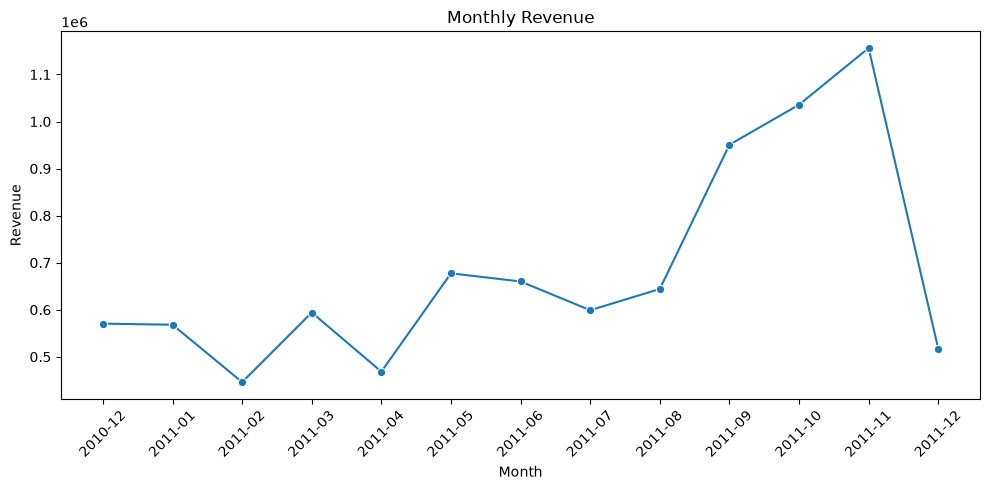

In [6]:
df["Month"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly = df.groupby("Month")["Revenue"].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="Month", y="Revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue")
plt.tight_layout()
plt.savefig("../images/monthly_revenue.png", dpi=150)
plt.show()


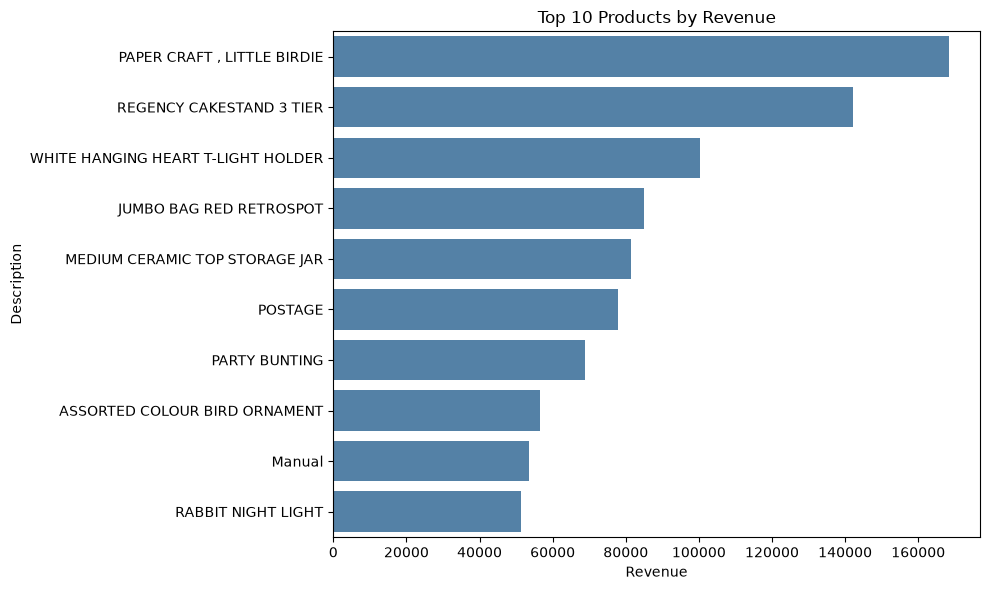

In [7]:
top = df.groupby("Description")["Revenue"].sum().nlargest(10).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=top, x="Revenue", y="Description", color="steelblue")
plt.title("Top 10 Products by Revenue")
plt.tight_layout()
plt.savefig("../images/top_products.png", dpi=150)
plt.show()


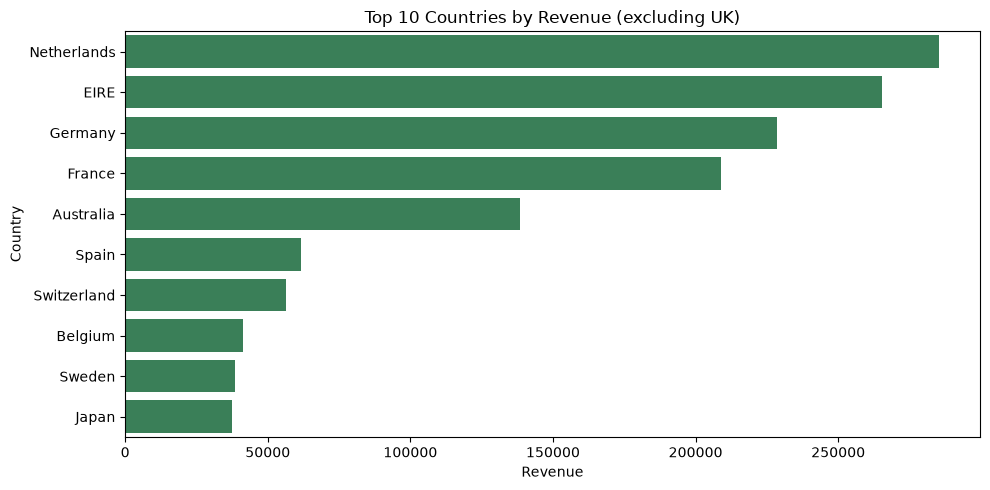

UK share of revenue: 82.0%


In [8]:
countries = (df[df["Country"] != "United Kingdom"]
             .groupby("Country")["Revenue"].sum().nlargest(10).reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=countries, x="Revenue", y="Country", color="seagreen")
plt.title("Top 10 Countries by Revenue (excluding UK)")
plt.tight_layout()
plt.savefig("../images/top_countries.png", dpi=150)
plt.show()

uk_share = df[df["Country"] == "United Kingdom"]["Revenue"].sum() / df["Revenue"].sum()
print(f"UK share of revenue: {uk_share:.1%}")


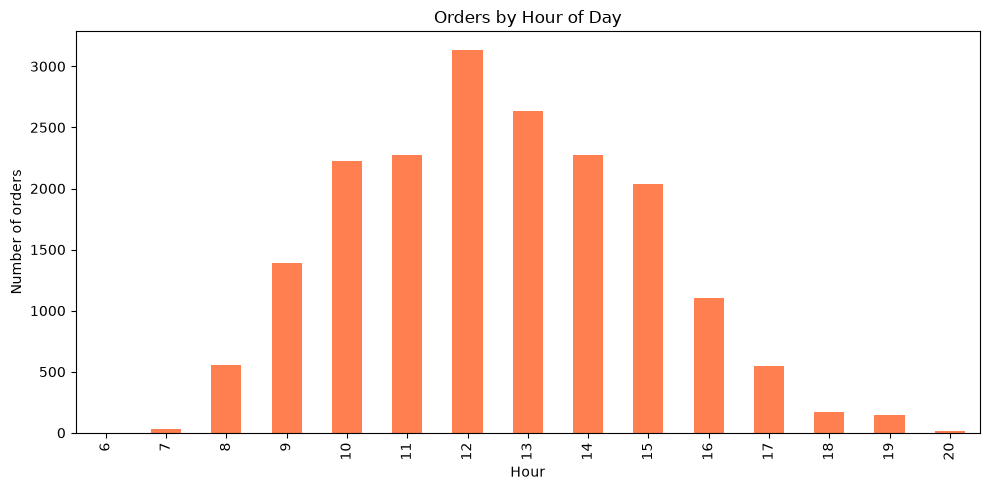

In [9]:
df["Hour"] = df["InvoiceDate"].dt.hour
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

hourly = df.groupby("Hour")["InvoiceNo"].nunique()
plt.figure(figsize=(10, 5))
hourly.plot(kind="bar", color="coral")
plt.title("Orders by Hour of Day")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.savefig("../images/orders_by_hour.png", dpi=150)
plt.show()


In [10]:
fig = px.line(monthly, x="Month", y="Revenue", title="Monthly Revenue (interactive)", markers=True)
fig.show()


In [11]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned file saved successfully.")


Cleaned file saved successfully.


In [12]:
df.to_csv("../data/cleaned_data.csv", index=False)
print("Cleaned data file saved successfully in data/ folder.")


Cleaned data file saved successfully in data/ folder.


In [13]:
# Set a baseline timeline anchor point (1 day past the maximum invoice date)
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Group transactions by customer to compile baseline RFM metrics
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM Matrix Dimensions:", rfm.shape)
rfm.describe()


RFM Matrix Dimensions: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


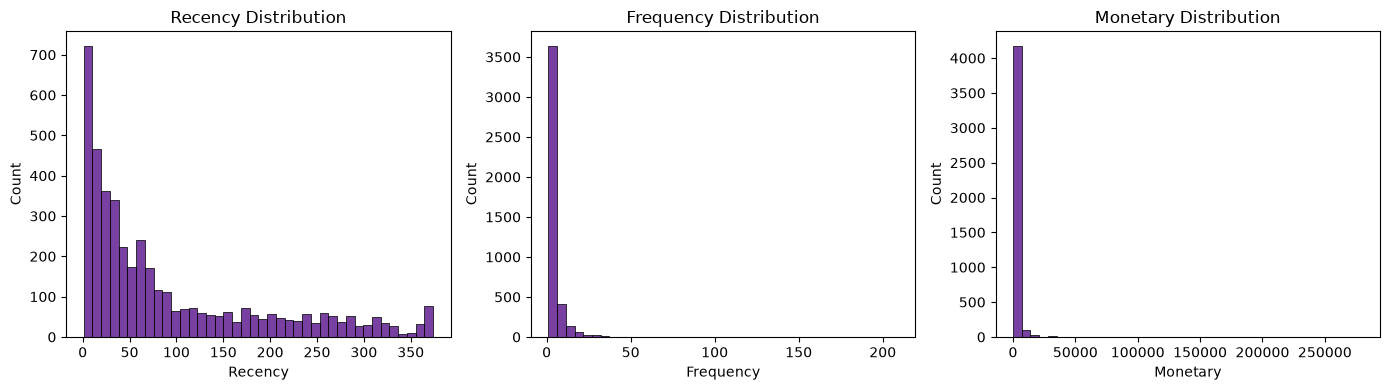

In [14]:
# Visualize the distributional spread across metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax, color="indigo")
    ax.set_title(f"{col} Distribution")
plt.tight_layout()
plt.savefig("../images/rfm_distributions.png", dpi=150)
plt.show()


In [15]:
from sklearn.preprocessing import StandardScaler

# Log transform metrics using log1p to manage zero-index skew variations smoothly
rfm_log = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])

# Scale metrics into unit variance (z-score scaling normalization)
X_scaled = StandardScaler().fit_transform(rfm_log)
print("Standardized Data Matrix Shape:", X_scaled.shape)


Standardized Data Matrix Shape: (4338, 3)


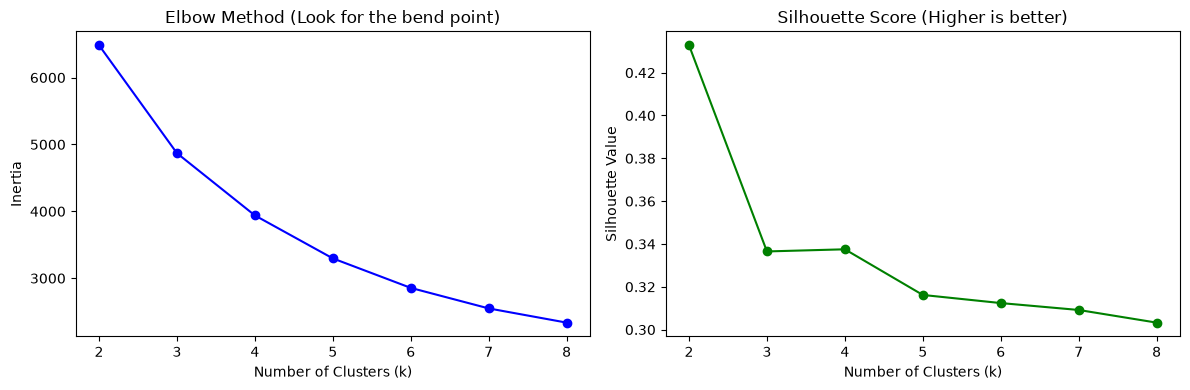

In [16]:
import warnings
import os
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Prevent joblib and system warnings from cluttering the output log area
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Explicitly sets the core allocation configuration

inertia, sil = [], []
K = range(2, 9)

# 2. Iteratively evaluate variance and cohesion metrics for cluster ranges
for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

# 3. Plot evaluation metrics dashboard cleanly
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, inertia, marker="o", color="blue")
ax[0].set_title("Elbow Method (Look for the bend point)")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("Inertia")

ax[1].plot(K, sil, marker="o", color="green")
ax[1].set_title("Silhouette Score (Higher is better)")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Silhouette Value")

plt.tight_layout()
plt.savefig("../images/choose_k.png", dpi=150)
plt.show()



In [17]:
# Initialize and predict final labels
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

# Aggregate profiles to discover cluster core properties
profile = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(1)

profile["Revenue_Share_%"] = (profile["Total_Revenue"] / profile["Total_Revenue"].sum() * 100).round(1)
profile


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Revenue_Share_%
Cluster,,,,,,
0,713,12.2,13.8,8088.0,5766757.1,64.9
1,1622,181.5,1.3,341.0,553099.8,6.2
2,837,17.7,2.2,557.3,466479.0,5.2
3,1166,71.6,4.1,1801.8,2100873.0,23.6


In [18]:
# EXAMINE YOUR PROFILE TABLE: Match the labels based on real mean values
# Example Mapping (Verify your cluster index traits first!):
# Champions = Lowest Recency, Highest Frequency, Highest Monetary
# At-Risk/Lost = Highest Recency, Lowest Frequency, Lowest Monetary
segment_names = {
    0: "Loyal Customers",
    1: "At-Risk / Lost",
    2: "Champions",
    3: "New / Occasional"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)
print(rfm["Segment"].value_counts())


Segment
At-Risk / Lost      1622
New / Occasional    1166
Champions            837
Loyal Customers      713
Name: count, dtype: int64


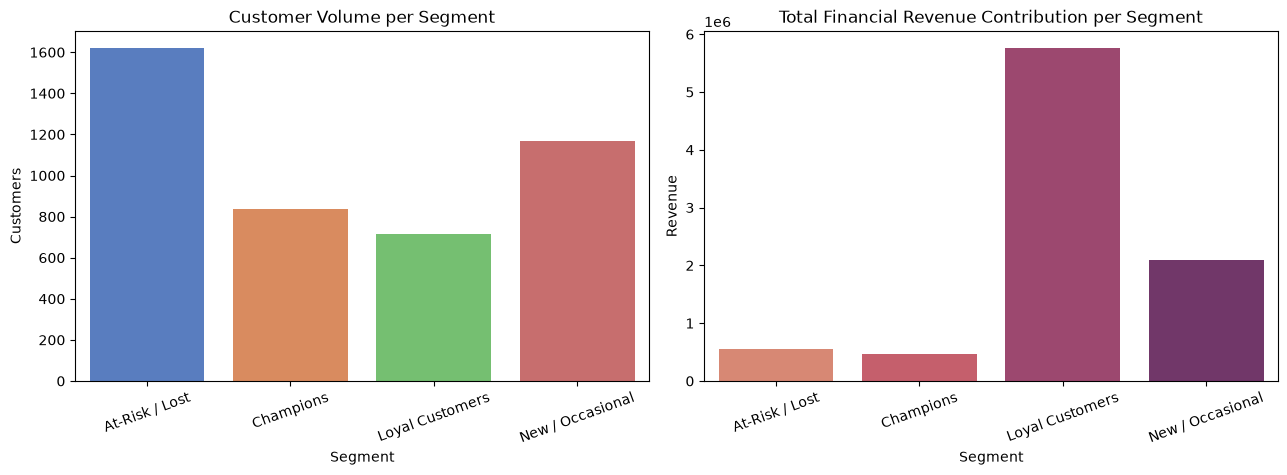

In [19]:
# 1. Group and aggregate segment summaries
seg_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    Revenue=("Monetary", "sum")
).reset_index()

# 2. Initialize side-by-side plot frames
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Customer volume with strict Seaborn hue settings to fix the warning
sns.barplot(
    data=seg_summary, 
    x="Segment", 
    y="Customers", 
    ax=ax[0], 
    palette="muted", 
    hue="Segment", 
    legend=False
)
ax[0].set_title("Customer Volume per Segment")
ax[0].tick_params(axis="x", rotation=20)

# Plot 2: Revenue generation with strict Seaborn hue settings to fix the warning
sns.barplot(
    data=seg_summary, 
    x="Segment", 
    y="Revenue", 
    ax=ax[1], 
    palette="flare", 
    hue="Segment", 
    legend=False
)
ax[1].set_title("Total Financial Revenue Contribution per Segment")
ax[1].tick_params(axis="x", rotation=20)

# 3. Clean spacing parameters and export image to your tracking directory
plt.tight_layout()
plt.savefig("../images/segment_summary.png", dpi=150)
plt.show()



In [20]:
fig = px.scatter_3d(rfm, x="Recency", y="Frequency", z="Monetary",
                    color="Segment", opacity=0.7,
                    title="Customer Segments (Interactive 3D RFM Model)")
fig.show()


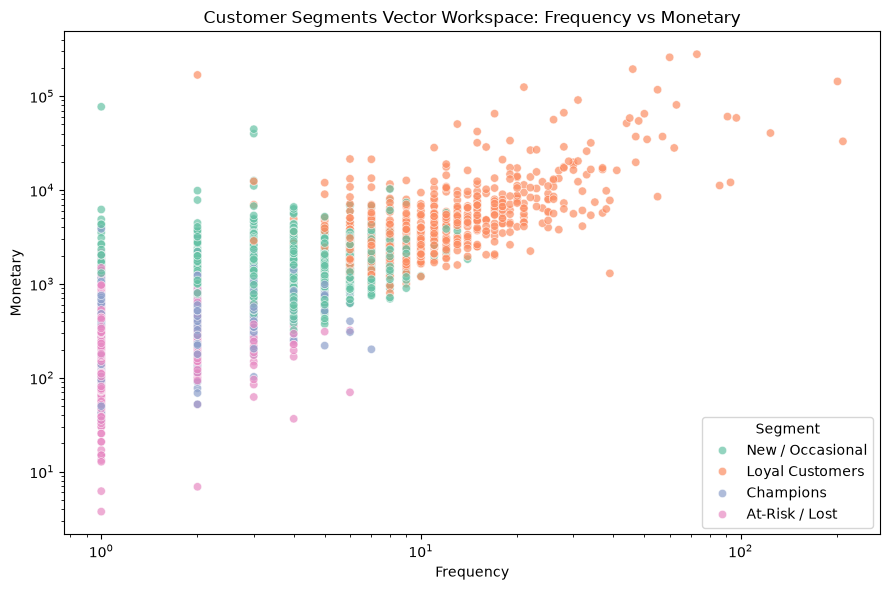

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Segment", alpha=0.7, palette="Set2")
plt.xscale("log")
plt.yscale("log")
plt.title("Customer Segments Vector Workspace: Frequency vs Monetary")
plt.tight_layout()
plt.savefig("../images/segments_scatter.png", dpi=150)
plt.show()


In [22]:
rfm.to_csv("../data/customer_segments.csv", index=False)
print("Customer segment data saved locally.")


Customer segment data saved locally.


In [23]:
# Run this to get your exact percentage distributions for interviews
summary_df = rfm.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Total_Revenue=("Monetary", "sum")
)
summary_df["Customer_%"] = (summary_df["Customer_Count"] / summary_df["Customer_Count"].sum() * 100).round(1)
summary_df["Revenue_%"] = (summary_df["Total_Revenue"] / summary_df["Total_Revenue"].sum() * 100).round(1)
print(summary_df)


                  Customer_Count  Total_Revenue  Customer_%  Revenue_%
Segment                                                               
At-Risk / Lost              1622     553099.771        37.4        6.2
Champions                    837     466479.030        19.3        5.2
Loyal Customers              713    5766757.070        16.4       64.9
New / Occasional            1166    2100873.023        26.9       23.6


In [24]:
# 1. Isolate the core UK transactional database
uk = df[df["Country"] == "United Kingdom"].copy()
uk["Description"] = uk["Description"].str.strip()

# 2. Extract the names of the top 150 most popular products
top_items = uk["Description"].value_counts().head(150).index
uk = uk[uk["Description"].isin(top_items)]

# 3. Pivot the table into a sparse product-order basket index matrix
basket = (uk.groupby(["InvoiceNo", "Description"])["Quantity"]
            .sum().unstack().fillna(0))

# 4. Convert numerical counts into clean True/False binary arrays
basket = basket.gt(0)

print("Total Structured Baskets (Orders Placed):", basket.shape[0])
print("Total Verified Unique Products Tracked:", basket.shape[1])


Total Structured Baskets (Orders Placed): 14155
Total Verified Unique Products Tracked: 150


In [26]:
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Discover item pairs passing a minimum support frequency index baseline of 2%
frequent = apriori(basket, min_support=0.02, use_colnames=True)
print("Total Frequent Itemsets Discovered:", len(frequent))

# 2. Extract association rules where the purchasing relationship strength is above a 1.2 lift multiplier
rules = association_rules(frequent, metric="lift", min_threshold=1.2, num_itemsets=len(frequent))
rules = rules.sort_values("lift", ascending=False).reset_index(drop=True)
print("Total Valid Behavioral Logic Rules Established:", len(rules))



Total Frequent Itemsets Discovered: 205
Total Valid Behavioral Logic Rules Established: 118


In [27]:
# Convert the messy frozenset clusters into standard text words
rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(list(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(list(x)))

# Filter out the top 10 absolute strongest product pairs by lift score
top_rules = rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(10).round(3)
top_rules


,antecedents,consequents,support,confidence,lift
0,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.021,0.748,24.344
1,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.021,0.690,24.344
2,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.024,0.557,20.593
3,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.024,0.890,20.593
4,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.024,0.692,20.569
5,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.024,0.716,20.569
6,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.029,0.660,18.954
7,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.029,0.819,18.954
8,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.022,0.670,18.749
9,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.022,0.619,18.749


In [28]:
top_rules.to_csv("../data/top_rules.csv", index=False)
print("Top rules matrix spreadsheet exported successfully to the data folder!")


Top rules matrix spreadsheet exported successfully to the data folder!


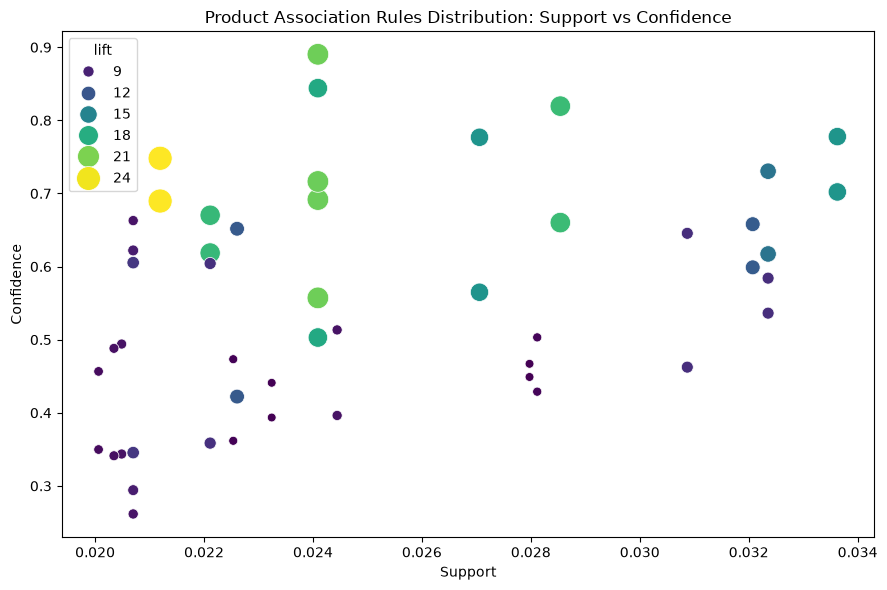

In [29]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rules.head(50), 
    x="support", 
    y="confidence",
    size="lift", 
    hue="lift", 
    sizes=(40, 300), 
    palette="viridis"
)
plt.title("Product Association Rules Distribution: Support vs Confidence")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.tight_layout()
plt.savefig("../images/association_rules.png", dpi=150)
plt.show()


In [ ]:
top10 = rules.head(10).copy()
top10["Rule"] = top10["antecedents"].str[:30] + " → " + top10["consequents"].str[:30]

plt.figure(figsize=(11, 6))
sns.barplot(data=top10, x="lift", y="Rule", color="darkorange")
plt.title("Top 10 High-Affinity Product Pairs Ranked by Lift")
plt.xlabel("Lift Score")
plt.ylabel("Product Cross-Selling Pairs")
plt.tight_layout()
plt.savefig("../images/top_rules_lift.png", dpi=150)
plt.show()
